In [1]:
from langgraph.graph import START,END,StateGraph
from langchain_huggingface import ChatHuggingFace,HuggingFaceEndpoint
from typing import TypedDict,Annotated
from pydantic import BaseModel,Field
from dotenv import load_dotenv
import operator

In [2]:
class Evaluation(BaseModel):
    
    feedback : str = Field(description="A detailed feedback of the essay")
    score : int = Field(description="Score for the essay out of 10", ge = 0, le = 10)

In [3]:
load_dotenv()

llm = HuggingFaceEndpoint(
    repo_id="openai/gpt-oss-20b",
    task = "text-generation"
)

model = ChatHuggingFace(llm = llm)

In [4]:
structured_model = model.with_structured_output(Evaluation.model_json_schema())

In [5]:
structured_model

_ChatModelBinding(bound=ChatHuggingFace(metadata={'lc_versions': {'langchain-core': '1.6.6', 'langchain': '0.3.26'}}, llm=HuggingFaceEndpoint(metadata={'lc_versions': {'langchain-core': '1.6.6', 'langchain': '0.3.26'}}, repo_id='openai/gpt-oss-20b', stop_sequences=[], server_kwargs={}, model_kwargs={}, model='openai/gpt-oss-20b', client=<InferenceClient(model='openai/gpt-oss-20b', timeout=120)>, async_client=<InferenceClient(model='openai/gpt-oss-20b', timeout=120)>, task='text-generation'), model_id='openai/gpt-oss-20b', temperature=0.8, top_p=0.95, max_tokens=512, model_kwargs={}), kwargs={'tools': [{'type': 'function', 'function': {'name': 'Evaluation', 'parameters': {'properties': {'feedback': {'description': 'A detailed feedback of the essay', 'title': 'Feedback', 'type': 'string'}, 'score': {'description': 'Score for the essay out of 10', 'maximum': 10, 'minimum': 0, 'title': 'Score', 'type': 'integer'}}, 'required': ['feedback', 'score'], 'type': 'object'}}}], 'ls_structured_out

In [6]:
essay = '''
Life is a combination of circumstances and choices. We cannot control every event that occurs, but we can often control how we respond to it. This ability to transform circumstances into meaningful action is an important measure of human character.
History provides several examples. Mahatma Gandhi faced racial discrimination in South Africa, but transformed his experience into a philosophy of non-violent resistance. Dr. B.R. Ambedkar experienced social discrimination but converted his struggles into a lifelong pursuit of equality and justice. Their circumstances did not determine the limits of their contribution; their responses did.
However, individual effort alone cannot overcome every structural disadvantage. Poverty, discrimination, illness and lack of opportunities can severely restrict choices. Therefore, governments and societies must create conditions through education, healthcare, social security and equal opportunities that enable individuals to exercise meaningful agency.
The same principle applies to nations. Economic crises, pandemics and natural disasters test not only resources but also the quality of institutions and leadership. A crisis can either deepen existing problems or become an opportunity for reform.
Ultimately, circumstances provide the starting point, but our responses influence the direction. Resilience, combined with compassion and institutional support, enables individuals and societies to transform adversity into opportunity.
'''

In [7]:
prompt = f'Evaluate the language quality of the following essay and provide a feedback and assign a score out of 10 : \n{essay}'

In [8]:
class UPSCState(BaseModel):
    essay: str
    language_feedback: str = ""
    cot_feedback: str = ""
    analysis_feedback: str = ""
    feedback: str = ""
    individual_scores: Annotated[list[int], operator.add] = Field(default_factory=list)
    average_score: float = 0.0

In [9]:
def evaluate_analysis(state: UPSCState):
    prompt = (
        f"Evaluate the language quality of the following essay and provide a feedback "
        f"and assign a score out of 10:\n{state.essay}"
    )
    result = structured_model.invoke(prompt)
    return {
        "analysis_feedback": result.feedback,
        "individual_scores": [result.score]
    }

def evaluate_cot(state: UPSCState):
    prompt = (
        f"Evaluate the clarity of thought of the following essay and provide a feedback "
        f"and assign a score out of 10:\n{state.essay}"
    )
    result = structured_model.invoke(prompt)
    return {
        "cot_feedback": result.feedback,
        "individual_scores": [result.score]
    }

def evaluate_language(state: UPSCState):
    prompt = (
        f"Evaluate the language fluency of the following essay and provide a feedback "
        f"and assign a score out of 10:\n{state.essay}"
    )
    result = structured_model.invoke(prompt)
    return {
        "language_feedback": result.feedback,
        "individual_scores": [result.score]
    }

def final_evaluation(state: UPSCState):
    prompt = (
        "Give a detailed feedback based on the following 3 feedbacks for the essay:\n"
        f"{state.language_feedback}\n{state.cot_feedback}\n{state.analysis_feedback}"
    )
    feedback = model.invoke(prompt).content
    score = sum(state.individual_scores) / len(state.individual_scores) if state.individual_scores else 0
    return {
        "feedback": feedback,
        "average_score": score
    }

In [10]:
graph = StateGraph(UPSCState)

In [11]:
graph.add_node("evaluate_cot",evaluate_cot)
graph.add_node("evaluate_language",evaluate_language)
graph.add_node("evaluate_analysis",evaluate_analysis)
graph.add_node("final_evaluation",final_evaluation)

In [12]:
graph.add_edge(START,'evaluate_analysis')
graph.add_edge(START,'evaluate_cot')
graph.add_edge(START,'evaluate_language')

graph.add_edge('evaluate_analysis','final_evaluation')
graph.add_edge('evaluate_cot','final_evaluation')
graph.add_edge('evaluate_language','final_evaluation')

graph.add_edge('final_evaluation',END)

In [13]:
workflow = graph.compile()

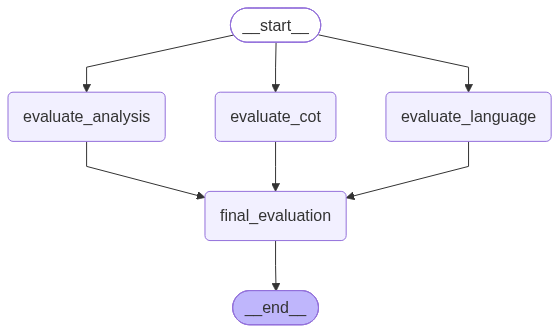

In [14]:
workflow

In [15]:
initial_state = {'essay':essay}

In [16]:
initial_state['essay']

'\nLife is a combination of circumstances and choices. We cannot control every event that occurs, but we can often control how we respond to it. This ability to transform circumstances into meaningful action is an important measure of human character.\nHistory provides several examples. Mahatma Gandhi faced racial discrimination in South Africa, but transformed his experience into a philosophy of non-violent resistance. Dr. B.R. Ambedkar experienced social discrimination but converted his struggles into a lifelong pursuit of equality and justice. Their circumstances did not determine the limits of their contribution; their responses did.\nHowever, individual effort alone cannot overcome every structural disadvantage. Poverty, discrimination, illness and lack of opportunities can severely restrict choices. Therefore, governments and societies must create conditions through education, healthcare, social security and equal opportunities that enable individuals to exercise meaningful agenc

In [19]:
workflow.invoke(initial_state)

AttributeError: 'dict' object has no attribute 'feedback'